##Covariance and Correlation in Machine Learning:
###What is Covariance?
Covariance measures how two variables move together. It gives insight into whether the variables have a positive, negative, or no relationship.

Positive Covariance: When one variable increases, the other variable also increases.

Negative Covariance: When one variable increases, the other variable decreases.

Zero Covariance: The two variables are unrelated; one change doesn’t tell us anything about the other.

The formula for calculating covariance between two variables (X) and (Y) is:

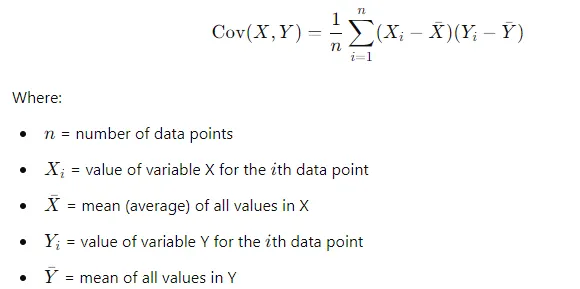
###Correlation
1. In covariance we find the relationship between variables but it doesn't find the strength of the relation. This problem is resolved by correlation. So It is a standardized version of covariance that measures both the direction and strength of the linear relationship between two variables by dividing covariance by the product of the standard deviations of the variables.


2. This results in a dimensionless value ranging from -1 to +1, where values close to +1 or -1 indicate strong positive or negative linear relationships, respectively, and 0 implies no linear relationship. The diagonal of the matrix always contains 1s, as each feature is perfectly correlated with itself.

3. The formula of correlation is given below:
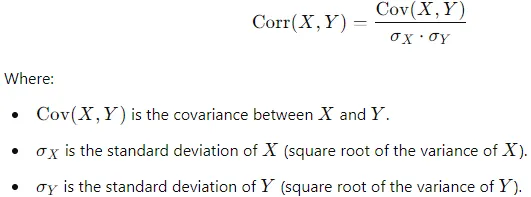
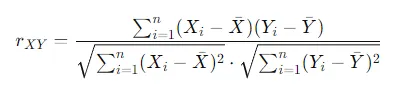


In [1]:
# Example: Hours Studied (X) and Exam Scores (Y)
hours_studied = [2, 4, 6, 8, 10]
exam_scores = [50, 60, 70, 80, 90]

# Step 1: Calculate the mean of both lists
mean_X = sum(hours_studied) / len(hours_studied)
mean_Y = sum(exam_scores) / len(exam_scores)

# Step 2: Calculate the differences from the mean for each data point
diff_X = [x - mean_X for x in hours_studied]
diff_Y = [y - mean_Y for y in exam_scores]

# Step 3: Multiply the differences for corresponding X and Y values
products = [diff_X[i] * diff_Y[i] for i in range(len(hours_studied))]

# Step 4: Sum the products
sum_products = sum(products)

# Step 5: Divide by the number of data points to get the covariance
covariance = sum_products / len(hours_studied)

# Output the result
print(f"Covariance between hours studied and exam scores: {covariance}")


Covariance between hours studied and exam scores: 40.0


Covariance Matrix:
 [[ 10.  50.]
 [ 50. 250.]]


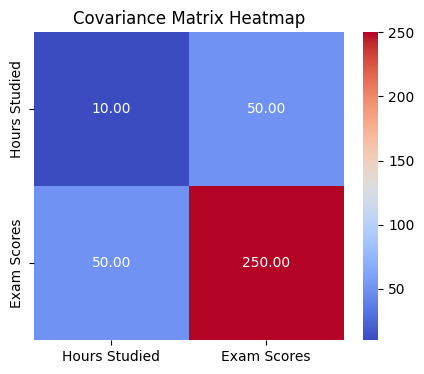

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Data: Hours studied (X) and Exam scores (Y)
hours_studied = [2, 4, 6, 8, 10]
exam_scores = [50, 60, 70, 80, 90]

# Stack the data into a 2D array (each row is a data point, each column is a variable)
data = np.array([hours_studied, exam_scores])

# Calculate the covariance matrix using NumPy's cov function
cov_matrix = np.cov(data)

# Print the covariance matrix
print("Covariance Matrix:\n", cov_matrix)

# Plotting the covariance matrix as a heatmap
plt.figure(figsize=(5,4))
sns.heatmap(cov_matrix, annot=True, fmt=".2f", cmap="coolwarm", xticklabels=["Hours Studied", "Exam Scores"], yticklabels=["Hours Studied", "Exam Scores"])
plt.title("Covariance Matrix Heatmap")
plt.show()

Covariance to Correlation:

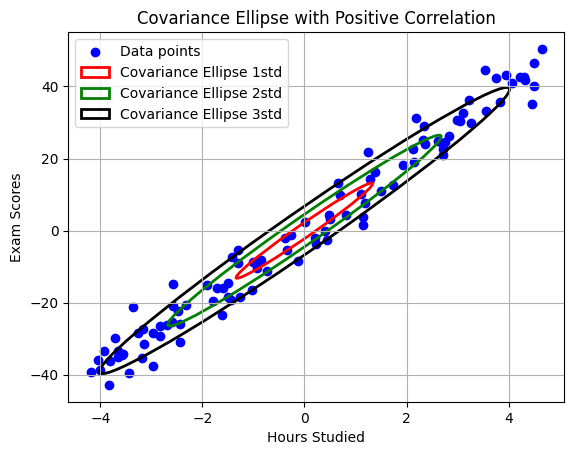

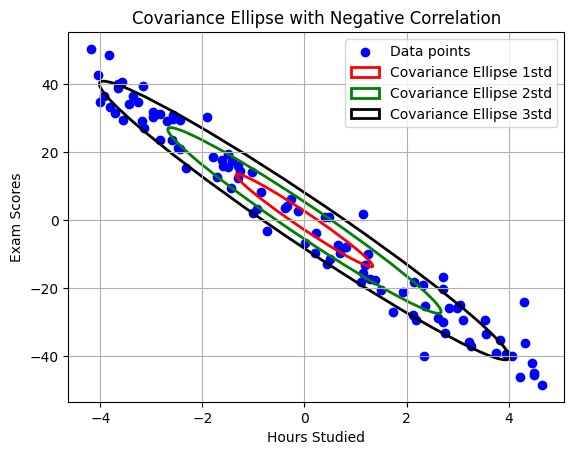

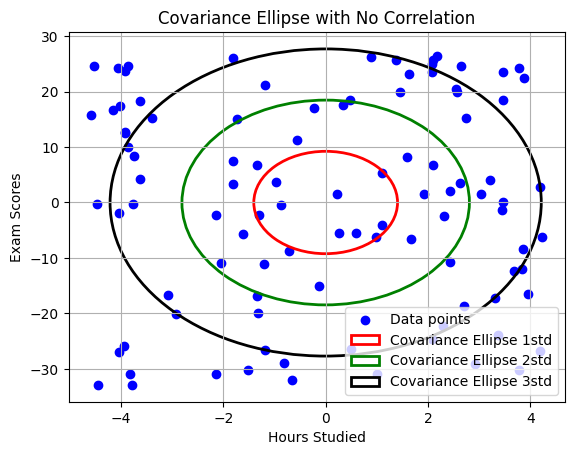

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse

def plot_covariance_ellipse(hours_studied, exam_scores, title):
    mean_X = np.mean(hours_studied)
    mean_Y = np.mean(exam_scores)
    hours_studied, exam_scores=hours_studied-mean_X, exam_scores-mean_Y
    # Stack the data and calculate the covariance matrix
    data = np.vstack((hours_studied, exam_scores))
    cov_matrix = np.cov(data, rowvar=True)

    # Means of hours_studied and exam_scores


    # Eigenvalues and eigenvectors of the covariance matrix
    eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

    # Compute angle for the ellipse (convert from radians to degrees)
    angle = np.arctan2(*eigenvectors[:, 0][::-1]) * 180 / np.pi

    # Width and height of the ellipse (1 standard deviations in each direction)
    width, height = np.sqrt(eigenvalues)

    # Plot data points
    plt.scatter(hours_studied, exam_scores, color='blue', label='Data points')

    # Plot the covariance ellipse centered at the mean of the data
    plt.gca().add_patch(Ellipse((0,0), width, height, angle=angle, edgecolor='red', facecolor='none', lw=2, label='Covariance Ellipse 1std'))
    plt.gca().add_patch(Ellipse((0,0), 2*width,2* height, angle=angle, edgecolor='green', facecolor='none', lw=2, label='Covariance Ellipse 2std'))
    plt.gca().add_patch(Ellipse((0,0), 3*width,3* height, angle=angle, edgecolor='black', facecolor='none', lw=2, label='Covariance Ellipse 3std'))

    # Add labels and title
    plt.title(title)
    plt.xlabel('Hours Studied')
    plt.ylabel('Exam Scores')
    plt.grid(True)

    # Add legend
    plt.legend()

    # Adjust axis limits for better visibility (based on ellipse size and data)
    x_padding = width / 2
    y_padding = height / 2

    #plt.xlim(hours_studied-mean_X , hours_studied+mean_X )
    #plt.ylim(exam_scores-mean_Y , exam_scores+mean_Y )

    # Show plot
    plt.show()

# Positive correlation data (as previously)
np.random.seed(42)
hours_studied_pos = np.random.uniform(1, 10, 100)
exam_scores_pos = 10 * hours_studied_pos + np.random.normal(0, 5, size=hours_studied_pos.shape)
plot_covariance_ellipse(hours_studied_pos, exam_scores_pos, 'Covariance Ellipse with Positive Correlation')

# Negative correlation data
exam_scores_neg = -10 * hours_studied_pos + np.random.normal(0, 5, size=hours_studied_pos.shape) + 100  # Shift to ensure positive values
plot_covariance_ellipse(hours_studied_pos, exam_scores_neg, 'Covariance Ellipse with Negative Correlation')


# No correlation data
hours_studied_no = np.random.uniform(1, 10, 100)
exam_scores_no = np.random.uniform(40, 100, 100)  # Completely random, independent of hours_studied
plot_covariance_ellipse(hours_studied_no, exam_scores_no, 'Covariance Ellipse with No Correlation')


 Corelation and Covariance matrix


A covariance matrix is a square matrix that shows the covariance between multiple variables. It gives us a clearer picture of how different variables in a dataset relate to one another.

For example, if we have two variables X(Hours Studied) and Y(Exam Scores), the covariance matrix will be a 2x2 matrix where:

The diagonal elements show the variance of each variable (Cov(X, X) and Cov(Y, Y)).
The off-diagonal elements show the covariance between the different variables (Cov(X, Y) and Cov(Y, X)).
In our case, we only have two variables (Hours Studied and Exam Scores), so the covariance matrix will look like this:

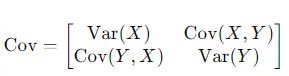

In [4]:
# Calculate the standard deviations (square root of diagonal elements)
std_devs = np.sqrt(np.diag(cov_matrix))

# Outer product of standard deviations to form the denominator matrix
denominator_matrix = np.outer(std_devs, std_devs)

# Calculate correlation matrix
correlation_matrix = cov_matrix / denominator_matrix

# Set the diagonal elements to 1 (just to be sure, though they should already be 1)
np.fill_diagonal(correlation_matrix, 1)

print("Covariance Matrix:\n", cov_matrix)
print("Correlation Matrix:\n", correlation_matrix)


Covariance Matrix:
 [[ 10.  50.]
 [ 50. 250.]]
Correlation Matrix:
 [[1. 1.]
 [1. 1.]]


Principle component Analysis (PCA):
“Principal Component Analysis (PCA) is a dimensionality reduction technique commonly used in machine learning and statistics. Its primary purpose is to transform a high-dimensional dataset into a lower-dimensional space while retaining as much of the original data’s variability as possible. In other words, PCA helps simplify complex datasets by finding a new set of orthogonal axes (principal components) along which the data points vary the most.”


*  Here’s how covariance is incorporated into PCA:

Step 1: Standardize the Data — Before performing PCA, the data is typically standardized (i.e., each feature is scaled to have a mean of 0 and standard deviation of 1). This ensures that features with different units of measurement do not disproportionately influence the results.

Step 2: Covariance Matrix—After standardizing, the next step is to compute the dataset's covariance matrix. Covariance measures how much two variables change together.

Step 3: Eigenvectors and Eigenvalues — Once the covariance matrix is computed, PCA proceeds by finding the eigenvectors and eigenvalues of this matrix. The eigenvectors represent the directions of maximum variance (i.e., the principal components), while the eigenvalues represent the amount of variance explained by each principal component.

Step 4: Projection onto Principal Components — Finally, the original data is projected onto the new set of axes defined by the principal components. The first principal component corresponds to the direction of the largest variance in the data, and each subsequent component is orthogonal to the previous ones, capturing as much of the remaining variance as possible.

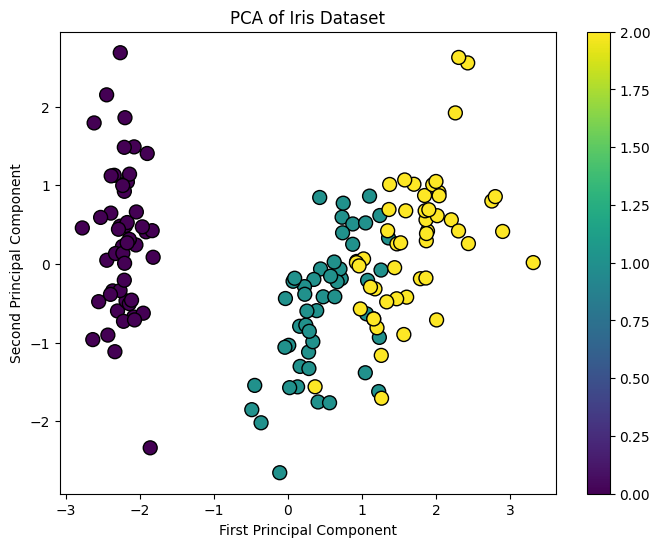

In [5]:
# Import the required libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler

# Load the Iris dataset
iris = load_iris()
X = iris.data  # Features
y = iris.target  # Labels

# Standardize the features (important for PCA)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply PCA to reduce to 2 principal components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Plot the two principal components
plt.figure(figsize=(8,6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='viridis', edgecolor='k', s=100)
plt.xlabel('First Principal Component')
plt.ylabel('Second Principal Component')
plt.title('PCA of Iris Dataset')
plt.colorbar()
plt.show()

Implementation of Principal Component Analysis in Python
Hence PCA uses a linear transformation that is based on preserving the most variance in the data using the least number of dimensions. It involves the following steps:

Step 1: Importing Required Libraries
We import the necessary library like pandas, numpy, scikit learn, seaborn and matplotlib to visualize results.

In [7]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

Step 2: Creating Sample Dataset
We make a small dataset with three features Height, Weight, Age and Gender.

In [8]:
data = {
    'Height': [170, 165, 180, 175, 160, 172, 168, 177, 162, 158],
    'Weight': [65, 59, 75, 68, 55, 70, 62, 74, 58, 54],
    'Age': [30, 25, 35, 28, 22, 32, 27, 33, 24, 21],
    'Gender': [1, 0, 1, 1, 0, 1, 0, 1, 0, 0]  # 1 = Male, 0 = Female
}
df = pd.DataFrame(data)
print(df)

   Height  Weight  Age  Gender
0     170      65   30       1
1     165      59   25       0
2     180      75   35       1
3     175      68   28       1
4     160      55   22       0
5     172      70   32       1
6     168      62   27       0
7     177      74   33       1
8     162      58   24       0
9     158      54   21       0


Step 3: Standardizing the Data
Since the features have different scales Height vs Age we standardize the data. This makes all features have mean = 0 and standard deviation = 1 so that no feature dominates just because of its units.

In [9]:
X = df.drop('Gender', axis=1)
y = df['Gender']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

Step 4: Applying PCA algorithm
We reduce the data from 3 features to 2 new features called principal components. These components capture most of the original information but in fewer dimensions.
We split the data into 70% training and 30% testing sets.
We train a logistic regression model on the reduced training data and predict gender labels on the test set.

In [12]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

X_train, X_test, y_train, y_test = train_test_split(X_pca, y, test_size=0.3, random_state=42)

model = LogisticRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

Step 5: Evaluating with Confusion Matrix
The confusion matrix compares actual vs predicted labels. This makes it easy to see where predictions were correct or wrong.

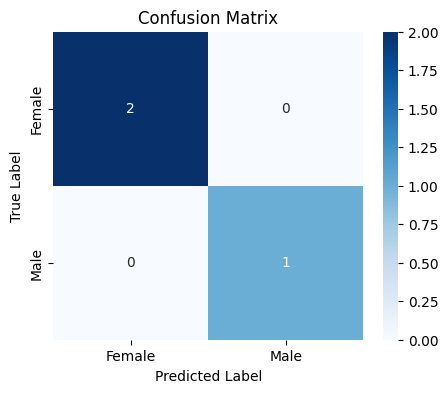

In [11]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Female', 'Male'], yticklabels=['Female', 'Male'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

Step 6: Visualizing PCA Result

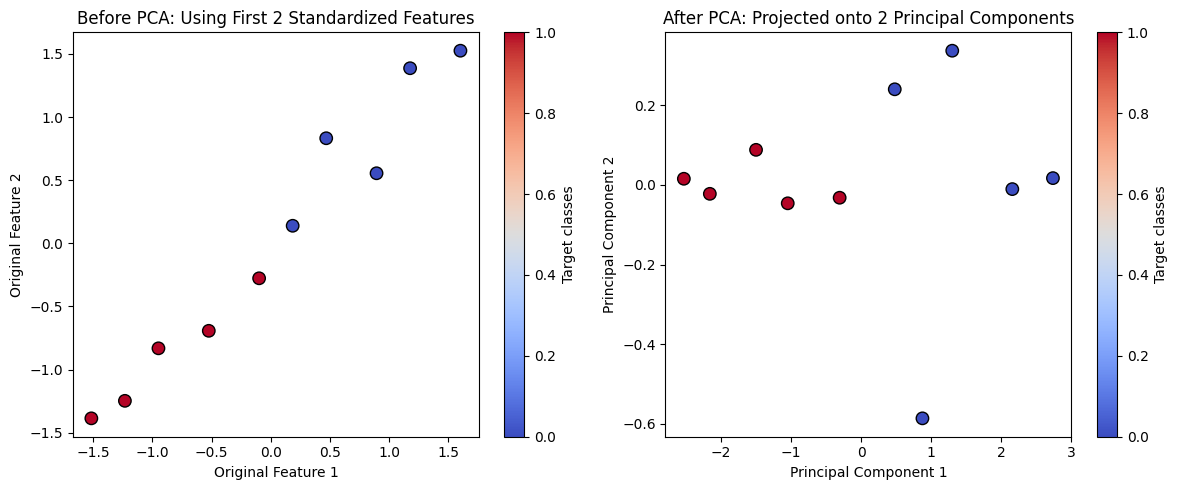

In [13]:
y_numeric = pd.factorize(y)[0]

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=y_numeric, cmap='coolwarm', edgecolor='k', s=80)
plt.xlabel('Original Feature 1')
plt.ylabel('Original Feature 2')
plt.title('Before PCA: Using First 2 Standardized Features')
plt.colorbar(label='Target classes')

plt.subplot(1, 2, 2)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y_numeric, cmap='coolwarm', edgecolor='k', s=80)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('After PCA: Projected onto 2 Principal Components')
plt.colorbar(label='Target classes')

plt.tight_layout()
plt.show()

1. Left Plot Before PCA: This shows the original standardized data plotted using the first two features. There is no guarantee of clear separation between classes as these are raw input dimensions.
2. Right Plot After PCA: This displays the transformed data using the top 2 principal components. These new components capture the maximum variance often showing better class separation and structure making it easier to analyze or model.


###Advantages
1. Multicollinearity Handling: Creates new, uncorrelated variables to address issues when original features are highly correlated.
2. Noise Reduction: Eliminates components with low variance enhance data clarity.
3. Data Compression: Represents data with fewer components reduce storage needs and speeding up processing.
4. Outlier Detection: Identifies unusual data points by showing which ones deviate significantly in the reduced space.
###Disadvantages
1. Interpretation Challenges: The new components are combinations of original variables which can be hard to explain.
2. Data Scaling Sensitivity: Requires proper scaling of data before application or results may be misleading.
3. Information Loss: Reducing dimensions may lose some important information if too few components are kept.
3. Assumption of Linearity: Works best when relationships between variables are linear and may struggle with non-linear data.
4. Computational Complexity: Can be slow and resource-intensive on very large datasets.

Correlation Application in ML models:
Reducing Correlation in Ensemble Methods:
Imagine a group of people trying to guess the number of jelly beans in a jar. If all the people have the same information and guess based on the same strategies, their guesses will likely be close to one another, leading to similar mistakes. But if each person uses a different strategy (one looks at the size of the jar, another considers the size of the beans, another uses random guesses), their errors will vary. When we average these diverse guesses, the final estimate is likely to be more accurate than any individual guess. This is how reducing correlation in ensemble models works: diverse predictions lead to a better collective result.

To summarize our example, Ensemble learning combines different models to minimize prediction variance. Highly correlated models lead to high combined model variance. Reducing the correlation between models reduces the likelihood of making the same mistakes. Diversity and randomness are crucial for reducing correlation and improving ensemble performance.

Specifically, In ensemble learning methods, such as Bagging (Bootstrap Aggregating) and Random Forests, the goal is to combine predictions from multiple base models (often decision trees) to create a stronger, more accurate model. A key factor in the success of these methods is the reduction of correlation between individual models.

Why Is Reducing Correlation Important?

When individual models (base learners) in an ensemble are highly correlated, they tend to make similar errors. For example, if all the models predict the same wrong output for a given input, the ensemble will not perform much better than any of the individual models. To gain an advantage from using multiple models, it is crucial that these models make diverse errors. The idea is that if one model makes a mistake, others might not, and the ensemble can “average out” these mistakes, leading to better overall performance.

The effectiveness of ensemble methods, such as Bagging and Random Forests, depends on error diversity across the models. By reducing correlation among the models, we ensure that the errors of the individual models are not correlated, leading to a more robust combined model.

In Bagging, each base model is trained on a different bootstrap sample from the original dataset, which means that each model sees a slightly different version of the dataset. This random sampling introduces variability between the models, helping to reduce their correlation. The aggregation (voting for classification or averaging for regression) of these diverse models results in a more stable and accurate final prediction.
Random Forests take Bagging a step further by introducing another source of randomness: random feature selection. At each split in a decision tree, Random Forests select a random subset of features instead of considering all available features. This random feature selection reduces the correlation between the trees because it forces the models to explore different parts of the feature space and make different splits, even if they are built on the same data. The combined effect of random sampling (from Bagging) and random feature selection results in a set of decision trees that are less correlated with each other.
Regularization in Linear Models:
Another excellent machine learning example where correlation is applied is Regularization in Linear Models. Specifically, Ridge Regression (also known as L2 Regularization) and Lasso Regression (also known as L1 Regularization) are techniques that incorporate correlation meaningfully.

 Ridge Regression and Correlation:
In linear regression models, multicollinearity (high correlation between independent variables) can cause instability in the model, as highly correlated features might over-influence the prediction, leading to overfitting. Ridge regression helps to reduce the impact of these correlated features by penalizing the size of the coefficients.


In Ridge and Lasso regression, regularization is key in mitigating the effects of multicollinearity (high correlation between independent variables). While Ridge regression reduces the size of the coefficients uniformly, Lasso performs feature selection by shrinking some coefficients to zero, thus handling correlated features more aggressively.

Correlation and Overfitting: When features are highly correlated, linear models can assign large weights to multiple features that essentially provide the same information. This leads to overfitting, as the model becomes too sensitive to slight variations in the training data.

1. Ridge Regression Formula: Ridge regression modifies the cost function of ordinary least squares by adding a penalty for large coefficients. The regularization term includes all feature coefficients, which helps to reduce the model’s reliance on highly correlated features. The formula for ridge regression is:

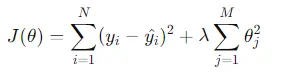


Here, λ is the regularization parameter that controls the strength of the penalty. As λ increases, the model reduces the magnitude of the coefficients, especially for features that are highly correlated with each other.

2. Lasso Regression and Feature Selection:
Lasso Regression is another regularization technique that also incorporates correlation but with a slightly different effect. Lasso regression uses L1 regularization, shrinks some feature coefficients to zero, effectively performing automatic feature selection. When two features are highly correlated, Lasso chooses only one, setting the other’s coefficient to zero. This helps reduce redundancy in the model.

Like Ridge regression, Lasso modifies the cost function by adding a penalty term, but here, the penalty is based on the absolute values of the coefficients.

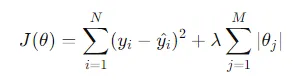

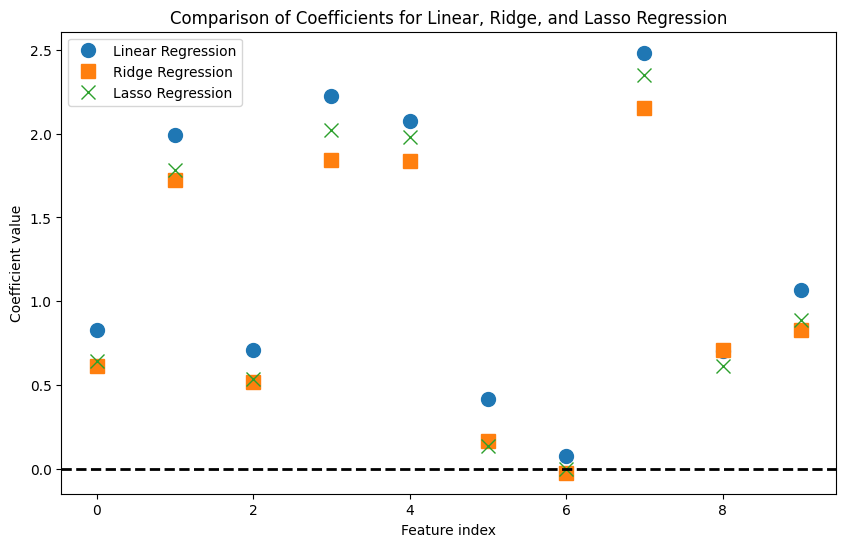

In [6]:
# Import necessary libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler

# Create a synthetic dataset with multicollinearity (highly correlated features)
# We'll use make_regression to generate data with 1000 samples, 20 features, and a small noise level
# 'effective_rank' creates correlated features
X, y = make_regression(n_samples=1000, n_features=10, noise=0.3, random_state=42, effective_rank=5)

# Split the dataset into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardize the data (important for regularization)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# --- Ordinary Least Squares (Linear Regression) ---
lin_reg = LinearRegression()
lin_reg.fit(X_train_scaled, y_train)

# --- Ridge Regression (L2 Regularization) with a large alpha ---
ridge_reg = Ridge(alpha=100)  # Use a large alpha to shrink coefficients more
ridge_reg.fit(X_train_scaled, y_train)

# --- Lasso Regression (L1 Regularization) with a moderate alpha ---
lasso_reg = Lasso(alpha=0.1)  # Lasso tends to set some coefficients to zero
lasso_reg.fit(X_train_scaled, y_train)

# Plot the coefficients to show how Ridge and Lasso affect them compared to Linear Regression
plt.figure(figsize=(10,6))

# Plot the coefficients from Linear Regression (no regularization)
plt.plot(lin_reg.coef_, 'o', label='Linear Regression', markersize=10)

# Plot the coefficients from Ridge Regression (L2 regularization)
plt.plot(ridge_reg.coef_, 's', label='Ridge Regression', markersize=10)

# Plot the coefficients from Lasso Regression (L1 regularization)
plt.plot(lasso_reg.coef_, 'x', label='Lasso Regression', markersize=10)

# Add a horizontal line at y=0 to make it easier to see where coefficients are being shrunk toward zero
plt.axhline(0, color='black', linestyle='--', lw=2)

# Add titles and labels
plt.title('Comparison of Coefficients for Linear, Ridge, and Lasso Regression')
plt.xlabel('Feature index')
plt.ylabel('Coefficient value')

# Add a legend to distinguish between the models
plt.legend()

# Show the plot
plt.show()